### *Linear Regression* ###

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.metrics import mean_absolute_error,  mean_squared_error

In [3]:
car_info = pd.read_csv('R:\\Gen AI\\Tech-Demo\\car data.csv')
car_info.columns=[cols.lower() for cols in car_info.columns]
car_info


,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [4]:
car_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   car_name       301 non-null    str    
 1   year           301 non-null    int64  
 2   selling_price  301 non-null    float64
 3   present_price  301 non-null    float64
 4   kms_driven     301 non-null    int64  
 5   fuel_type      301 non-null    str    
 6   seller_type    301 non-null    str    
 7   transmission   301 non-null    str    
 8   owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 30.0 KB


In [5]:
car_info.isna().sum()

car_name         0
year             0
selling_price    0
present_price    0
kms_driven       0
fuel_type        0
seller_type      0
transmission     0
owner            0
dtype: int64

In [6]:
car_info.describe()

,year,selling_price,present_price,kms_driven,owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [8]:
print(car_info['fuel_type'].value_counts())
print()
print(car_info['seller_type'].value_counts())
print()
print(car_info['transmission'].value_counts())

fuel_type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

seller_type
Dealer        195
Individual    106
Name: count, dtype: int64

transmission
Manual       261
Automatic     40
Name: count, dtype: int64


In [9]:
fuel_type = car_info['fuel_type']

seller_info = car_info['seller_type']

transmission_info = car_info['transmission']

selling_price = car_info['selling_price']

Text(0, 0.5, 'Selling Price')

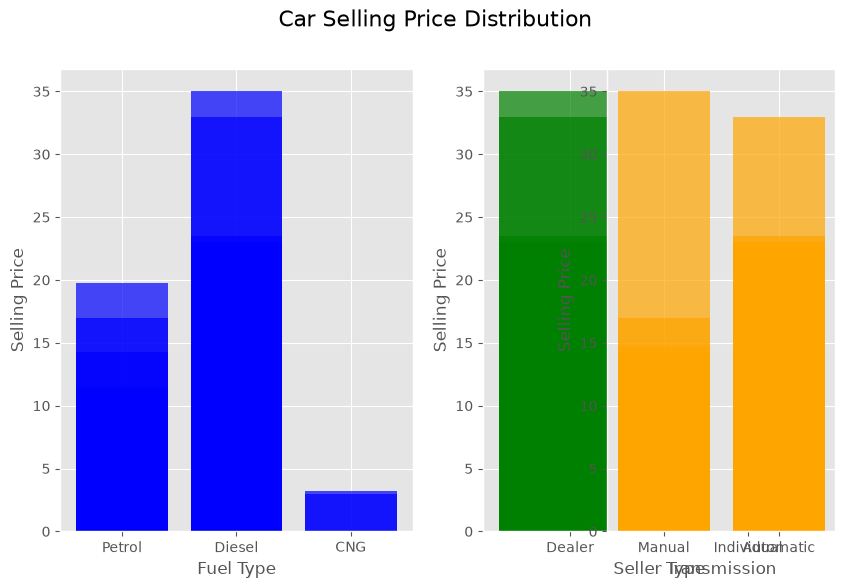

In [11]:
style.use('ggplot')

chart = plt.figure(figsize=(10, 6))

chart.suptitle('Car Selling Price Distribution', fontsize=16)
plt.subplot(1, 2, 1)
plt.bar(fuel_type, selling_price, color='blue', alpha=0.7)
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')

plt.subplot(1, 2, 2)
plt.bar(seller_info, selling_price, color='green', alpha=0.7)
plt.xlabel('Seller Type')
plt.ylabel('Selling Price')

plt.subplot(1, 3, 3)
plt.bar(transmission_info, selling_price, color='orange', alpha=0.7)
plt.xlabel('Transmission')
plt.ylabel('Selling Price')

In [13]:
petrol_data = car_info.groupby('fuel_type').get_group('Petrol')
petrol_data.describe()

,year,selling_price,present_price,kms_driven,owner
count,239.000000,239.000000,239.000000,239.000000,239.000000
mean,2013.539749,3.264184,5.583556,33528.937238,0.050209
std,3.042674,3.135537,5.290685,40308.984886,0.270368
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.600000,0.940000,13850.000000,0.000000
50%,2014.000000,2.650000,4.600000,25870.000000,0.000000
75%,2016.000000,5.200000,7.980000,44271.000000,0.000000
max,2017.000000,19.750000,23.730000,500000.000000,3.000000


In [14]:
diesel_data = car_info.groupby('fuel_type').get_group('Diesel')
diesel_data.describe()

,year,selling_price,present_price,kms_driven,owner
count,60.000000,60.000000,60.000000,60.000000,60.000000
mean,2014.000000,10.278500,15.814500,50369.916667,0.016667
std,2.201694,7.185159,13.484289,30021.446979,0.129099
min,2005.000000,3.100000,5.700000,2071.000000,0.000000
25%,2013.000000,5.137500,8.912500,38750.000000,0.000000
50%,2014.000000,7.750000,10.585000,45000.000000,0.000000
75%,2015.000000,12.600000,17.010000,59250.000000,0.000000
max,2018.000000,35.000000,92.600000,197176.000000,1.000000


***Convert categorical to numberical data***

In [15]:
car_info.replace({'fuel_type': {'Petrol': 0, 'Diesel': 1, 'CNG': 2}}, inplace=True)
car_info.replace({'seller_type': {'Dealer': 0, 'Individual': 1}}, inplace=True)
car_info.replace({'transmission': {'Manual': 0, 'Automatic': 1}},

,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,0,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,1,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,0,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,0,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,1,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,1,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,0,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,0,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,1,Dealer,Manual,0


<Axes: title={'center': 'Car Selling Price Distribution by Fuel Type'}, xlabel='present_price', ylabel='selling_price'>

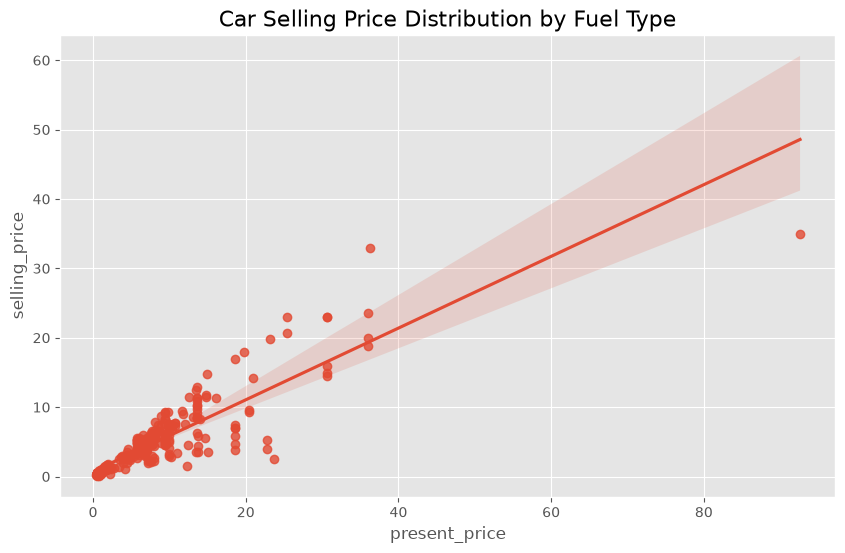

In [23]:
fig = plt.figure(figsize=(10, 6))

plt.title('Car Selling Price Distribution by Fuel Type', fontsize=16)
sns.regplot(x='present_price', y='selling_price', data=car_info)

***Input and Output data***

In [28]:
input_data = car_info.drop(['car_name', 'selling_price'], axis=1)
out_data = car_info["selling_price"]
input_data.head()

,year,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,2014,5.59,27000,0,Dealer,Manual,0
1,2013,9.54,43000,1,Dealer,Manual,0
2,2017,9.85,6900,0,Dealer,Manual,0
3,2011,4.15,5200,0,Dealer,Manual,0
4,2014,6.87,42450,1,Dealer,Manual,0


In [26]:
input_data.head()

,year,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,2014,5.59,27000,0,Dealer,Manual,0
1,2013,9.54,43000,1,Dealer,Manual,0
2,2017,9.85,6900,0,Dealer,Manual,0
3,2011,4.15,5200,0,Dealer,Manual,0
4,2014,6.87,42450,1,Dealer,Manual,0


In [29]:
out_data.head()

0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: selling_price, dtype: float64

In [30]:
input_data = pd.get_dummies(input_data, dtype=int)
print(input_data.head())

   year  present_price  ...  transmission_Automatic  transmission_Manual
0  2014           5.59  ...                       0                    1
1  2013           9.54  ...                       0                    1
2  2017           9.85  ...                       0                    1
3  2011           4.15  ...                       0                    1
4  2014           6.87  ...                       0                    1

[5 rows x 11 columns]


In [31]:
scalar = StandardScaler()
input_data = scalar.fit_transform(input_data)
print(input_data)

[[ 0.128897   -0.23621461 -0.25622446 ... -0.73728539 -0.39148015
   0.39148015]
 [-0.21751369  0.22150462  0.1559105  ... -0.73728539 -0.39148015
   0.39148015]
 [ 1.16812909  0.25742689 -0.77396901 ... -0.73728539 -0.39148015
   0.39148015]
 ...
 [-1.60315648  0.39068691  1.31334003 ... -0.73728539 -0.39148015
   0.39148015]
 [ 1.16812909  0.56450434 -0.7198763  ... -0.73728539 -0.39148015
   0.39148015]
 [ 0.8217184  -0.20029235 -0.81095812 ... -0.73728539 -0.39148015
   0.39148015]]


In [33]:
input_data_train, input_data_test, out_data_train, out_data_test = train_test_split(input_data, out_data)
print(input_data_train.shape)
print(input_data_test.shape)

(225, 11)
(76, 11)


In [34]:
model = LinearRegression()
model.fit(input_data_train, out_data_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 1.25, 4.39,-0.21,...,-0.12, 0.16,-0.16]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.616
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[28.06,22.09,18.56,..., 0. , 0. , 0. ]"


In [35]:
predicted_price = model.predict(input_data_test)
print(predicted_price)

[ 5.50385036  4.24980893  3.41266321  4.09199846  4.30322488  7.85729907
  5.08502213  2.84280466  4.20279641  5.20088003  0.19639525  1.8005211
 10.17280536  1.55515673  7.16660582  3.94553894 -1.12752605  8.14794162
  0.95981299  6.26364582  1.02170941  9.4330913   8.06006805  0.73899998
  1.45994527  4.88398771 10.06294837  8.57351306 -3.53479579  5.82116091
  0.06357033  0.50646825  2.13514281  7.59361565  4.72292373  1.17758067
  9.52652985  5.53362142  3.93181681 -2.97484695 -0.8133567  -1.32962484
  7.33261264  1.15441367  4.11436057  5.10735811 10.0419245  -1.12081055
 47.40643091  8.55507895  6.92160559  3.99154685  5.18738295  1.89855638
  4.32455947  2.82798476  6.31179402  4.07266673  0.43236876  1.07355765
  5.58850993  7.22761332  1.58470602  2.39640685  0.91438097  3.94911218
  5.35549309 -0.29552082  1.53714656  7.26951808 -0.20066521 14.83010711
  3.42608619  1.89203539  2.64315511  5.5899757 ]


In [36]:
print("mean_absolute_error: ", mean_absolute_error(out_data_test, predicted_price))
print("mean_squared_error: ", mean_squared_error(out_data_test, predicted_price))

mean_absolute_error:  1.2039115358178136
mean_squared_error:  3.9398393581100977
